In [83]:
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_predict, train_test_split, cross_validate, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.preprocessing import TargetEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBRegressor
import time
warnings.filterwarnings("ignore")

size_text = 18   # change this one number to scale all text
plt.rcParams.update({
    'font.size':        size_text,        # base size (text, annotations)
    'axes.titlesize':   size_text + 2,    # subplot titles
    'axes.labelsize':   size_text,        # x and y axis labels
    'xtick.labelsize':  size_text - 2,    # tick numbers
    'ytick.labelsize':  size_text - 2,
    'legend.fontsize':  size_text - 2,
    'figure.titlesize': size_text - 2,    # fig.suptitle
})

df=pd.read_csv("data.csv")


# --- DATA EXPLORATION/DESCRIPTION ---
column_names = df.columns
print("Column names in the dataset: \n", column_names)
print("Shape of the dataset: \n", df.shape)
shape_for = df.shape
    
df = df.drop(columns=["Unnamed: 0"], errors="ignore").copy() # dropping unnamed: 0, the index column

# Filtering the missing values
missing_values = df.isnull().sum()
#print("Missing values in each column: \n" , missing_values)
#print("Double rows for df: \n", df.duplicated().sum())


print("Shape of the dataset: \n", df.shape)


Column names in the dataset: 
 Index(['Unnamed: 0', 'brand', 'sale_price', 'fuel_type', 'location',
       'vehicle_model', 'mileage', 'year', 'body_style', 'vehicle_condition',
       'gearbox', 'engine_cylinders', 'drive_type', 'color', 'region',
       'vehicle_size', 'title'],
      dtype='str')
Shape of the dataset: 
 (97331, 17)
Shape of the dataset: 
 (97331, 16)


Numeric columns in the dataset: 
 Index(['sale_price', 'mileage', 'year'], dtype='str')
Basic statistics of the numerical columns:
          sale_price       mileage          year
count  9.733100e+04  9.635600e+04  97056.000000
mean   5.763063e+04  9.116786e+04   2012.005595
std    1.197861e+07  1.831625e+05      8.475459
min    0.000000e+00  0.000000e+00   1900.000000
25%    6.500000e+03  3.442500e+04   2009.000000
50%    1.499900e+04  7.954000e+04   2014.000000
75%    2.759000e+04  1.271622e+05   2017.000000
max    3.736929e+09  1.000000e+07   2022.000000
Double rows for numerical values: 
 29664
sale_price    14999.0
mileage       79540.0
year           2014.0
dtype: float64
sale_price    7389
mileage        474
year             0
dtype: int64


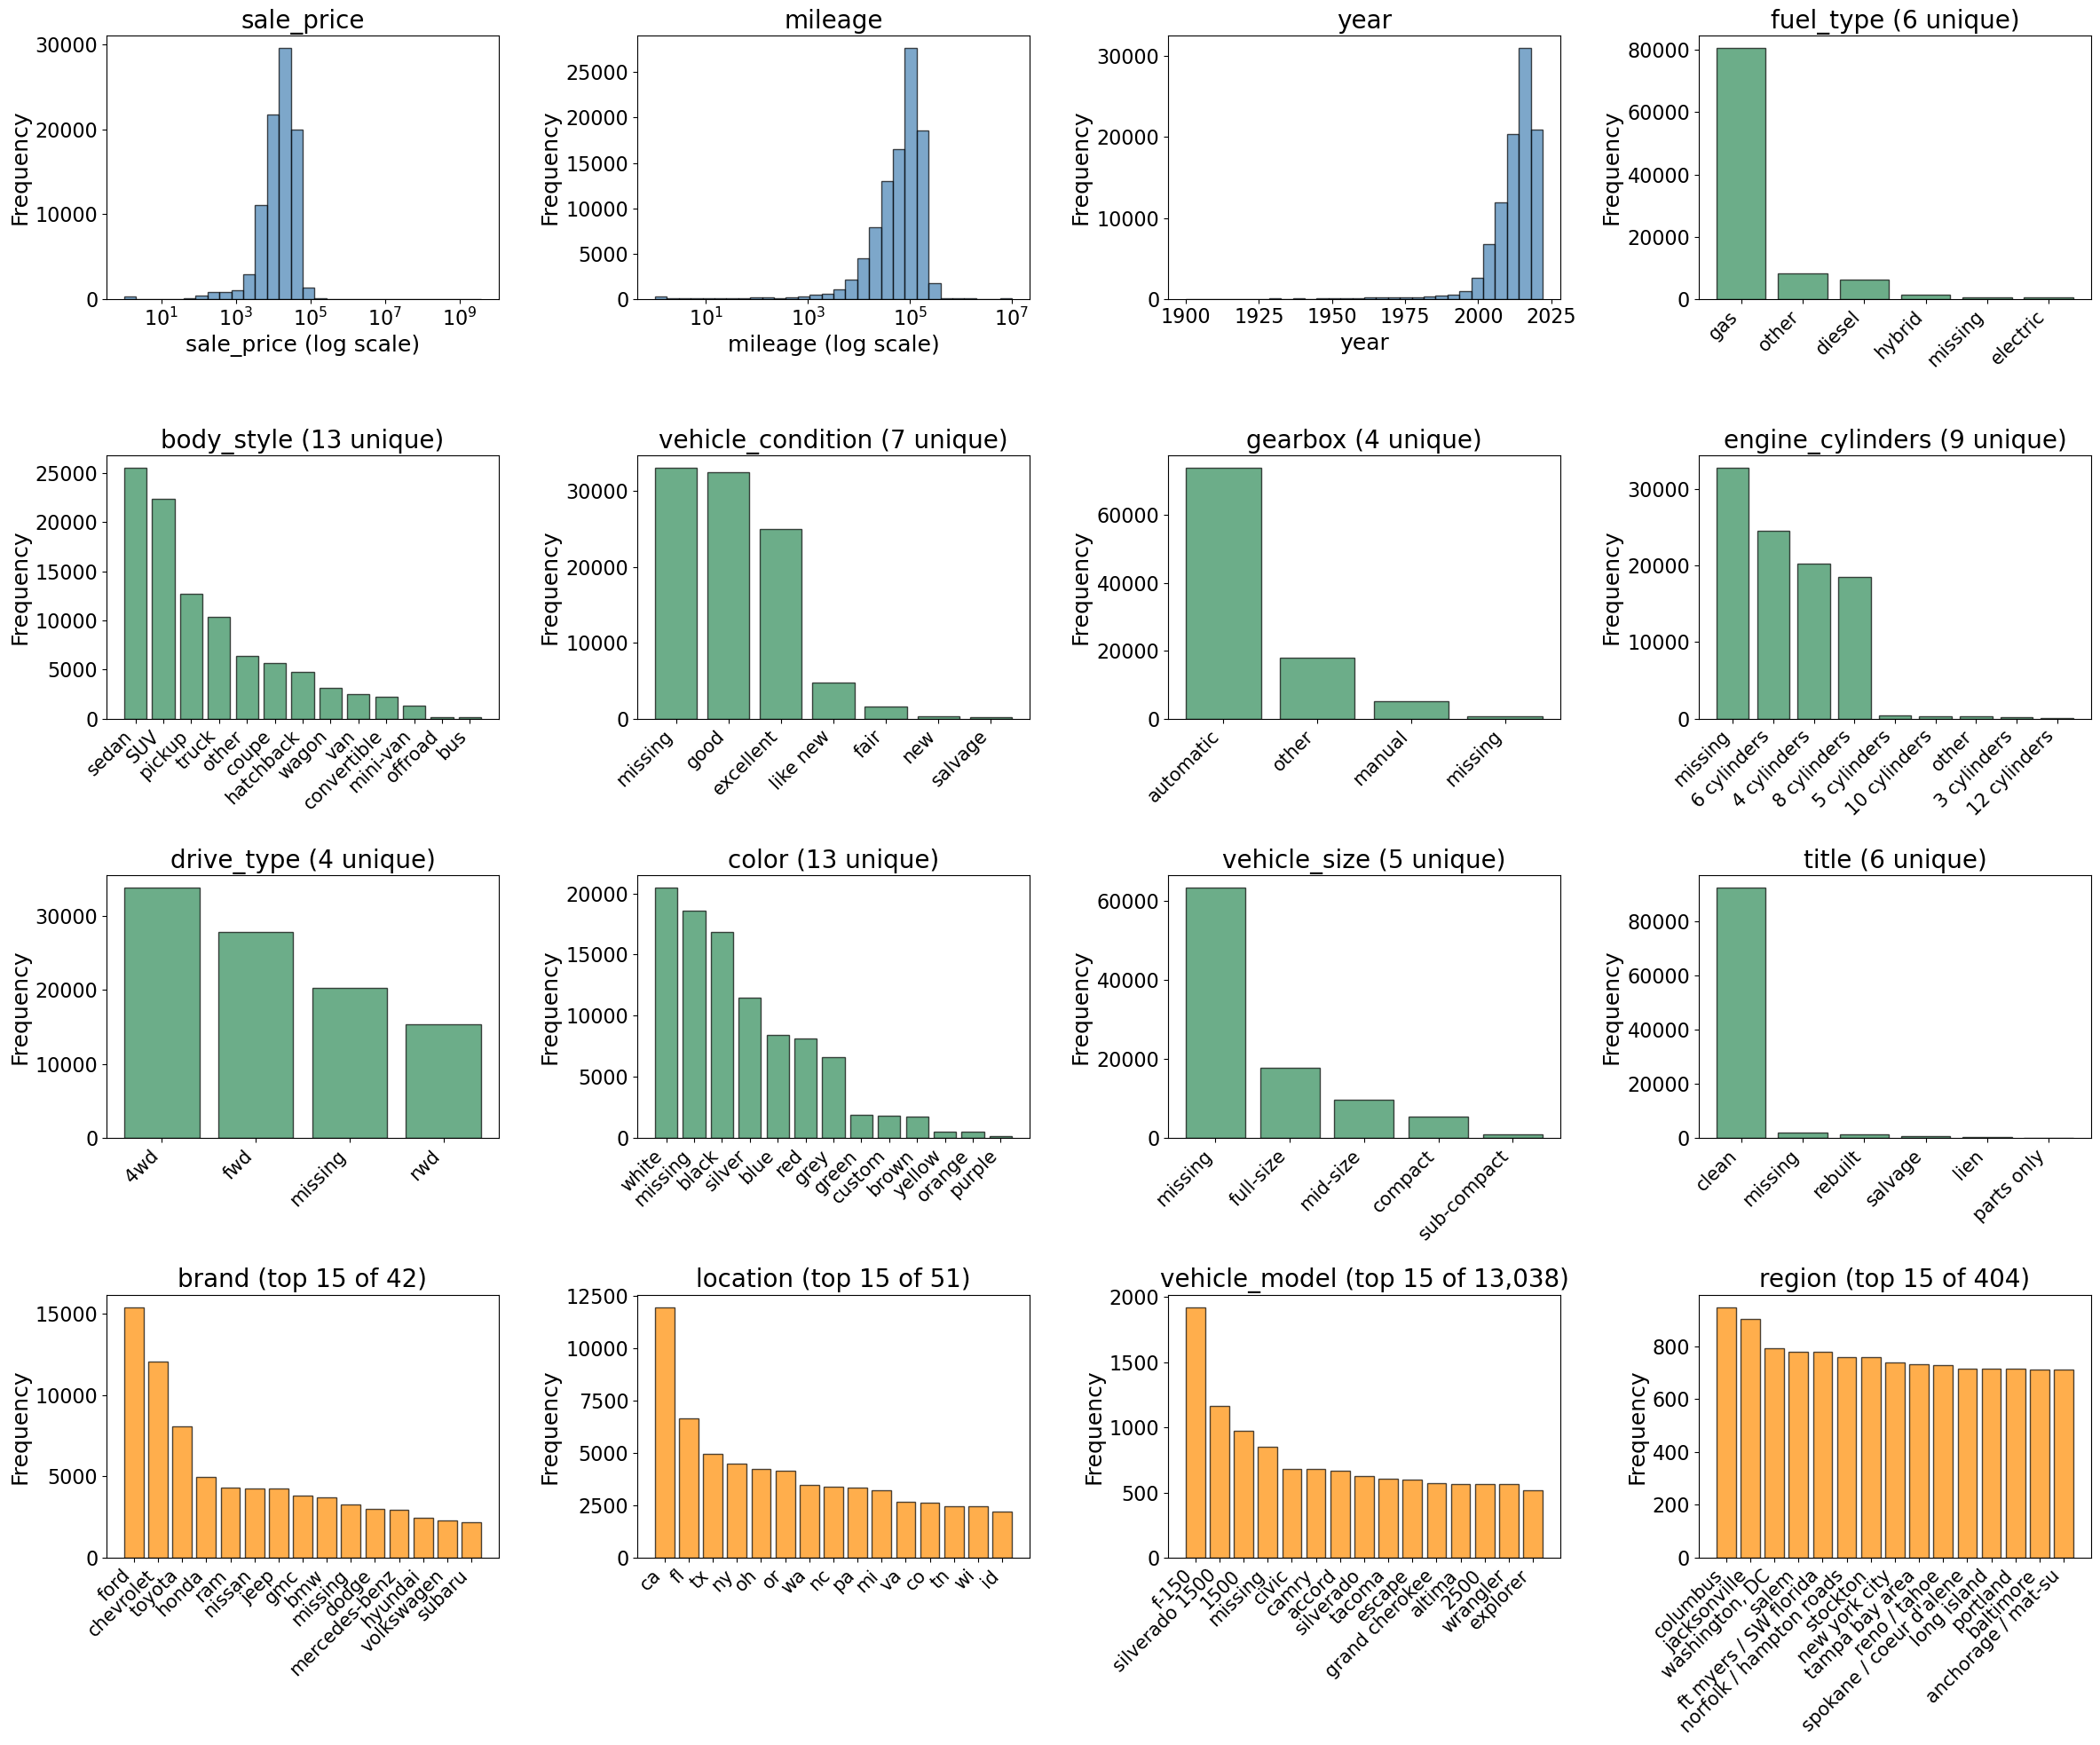

In [84]:
# NUMERICAL COLUMNS
# making correlation matrix with only the numeric columns
numeric_df = df.select_dtypes(include=['float64', 'int64'])
num_cols = numeric_df.columns
# removing the index row called 'Unnamed: 0' (this is the index column)
print("Numeric columns in the dataset: \n", numeric_df.columns)
print("Basic statistics of the numerical columns:\n", numeric_df.describe())
print("Double rows for numerical values: \n", numeric_df.duplicated().sum())
median_rows = numeric_df.median()
print(median_rows)
print((numeric_df == 0).sum())

# CATIGORICAL COLUMNS
# Looking at the unique values in the categorical columns
classes_df = df.select_dtypes(include=['object'])
cat_cols = classes_df.columns
classes_df_20 = classes_df.loc[:, classes_df.nunique() <= 20] # Selecting all rows and only the columns with less than or equal to 20 unique values (for shape plot)

TOP_N = 15                                  # labels shown for high-cardinality columns
log_x_cols = ["sale_price", "mileage"]      # very skewed raw values -> log-spaced bins

num_plot_cols = list(numeric_df.columns)                                         # 3
low_card_cols = list(classes_df_20.columns)                                      # 9
high_card_cols = [c for c in classes_df.columns if c not in classes_df_20.columns]  # 4

panels = ([(c, "num") for c in num_plot_cols]
          + [(c, "low") for c in low_card_cols]
          + [(c, "high") for c in high_card_cols])

colors = {"num": "steelblue", "low": "seagreen", "high": "darkorange"}

fig, axes = plt.subplots(4, 4, figsize=(24, 20))
axes = axes.ravel()

for ax, (col, kind) in zip(axes, panels):
    if kind == "num":
        data = numeric_df[col].dropna()
        if col in log_x_cols:
            data = data[data > 0]                       # log scale can't show 0
            bins = np.logspace(np.log10(data.min()), np.log10(data.max()), 31)
            ax.hist(data, bins=bins, edgecolor="black", alpha=0.7, color=colors[kind])
            ax.set_xscale("log")
            ax.set_xlabel(f"{col} (log scale)")
        else:
            ax.hist(data, bins=30, edgecolor="black", alpha=0.7, color=colors[kind])
            ax.set_xlabel(col)
        ax.set_title(col)
    else:
        counts = classes_df[col].fillna("missing").value_counts()   # NaN as its own bar
        n_unique = len(counts)
        if kind == "high":
            counts = counts.head(TOP_N)
            ax.set_title(f"{col} (top {TOP_N} of {n_unique:,})")
        else:
            ax.set_title(f"{col} ({n_unique} unique)")
        ax.bar(counts.index.astype(str), counts.values,
               edgecolor="black", alpha=0.7, color=colors[kind])
        ax.tick_params(axis="x", rotation=45, labelsize=15)
        plt.setp(ax.get_xticklabels(), ha="right")
    ax.set_ylabel("Frequency")

# hide unused cells (in case there are fewer than 16 features)
for ax in axes[len(panels):]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig("Figures/DataVisualization/overview_histograms.png", dpi=200, bbox_inches="tight")
plt.show()


In [85]:

df = df[(df["sale_price"] >= 500) & (df["sale_price"] <= 300_000)]
df = df[~(df["mileage"] > 500_000)]  

shape_after = df.shape
print(f"Removed lines impossible, dupes and filler values: \n", shape_for[0] - shape_after[0])
print(shape_after)
#dup_cols = [c for c in df.columns if c not in ["region", "location"]]
#df = df.drop_duplicates(subset=dup_cols)

numeric_df = df.select_dtypes(include=['float64', 'int64'])
classes_df = df.select_dtypes(include=['object'])
cat_cols = classes_df.columns
classes_df_20 = classes_df.loc[:, classes_df.nunique() <= 20]



Removed lines impossible, dupes and filler values: 
 9500
(87831, 16)


          feature  n_unique most_frequent  count  percent  n_missing  percent_missing
            title         6         clean  83291    94.83       1871             2.13
        fuel_type         5           gas  72867    82.96        548             0.62
          gearbox         3     automatic  65333    74.38        424             0.48
vehicle_condition         6          good  31661    36.05      27103            30.86
       drive_type         3           4wd  30146    34.32      18358            20.90
       body_style        13         sedan  22885    26.06          0             0.00
 engine_cylinders         8   6 cylinders  22596    25.73      29049            33.07
            color        12         white  18506    21.07      15465            17.61
     vehicle_size         4     full-size  15936    18.14      57386            65.34
            brand        41          ford  13742    15.65       3002             3.42
         location        51            ca  10415    11

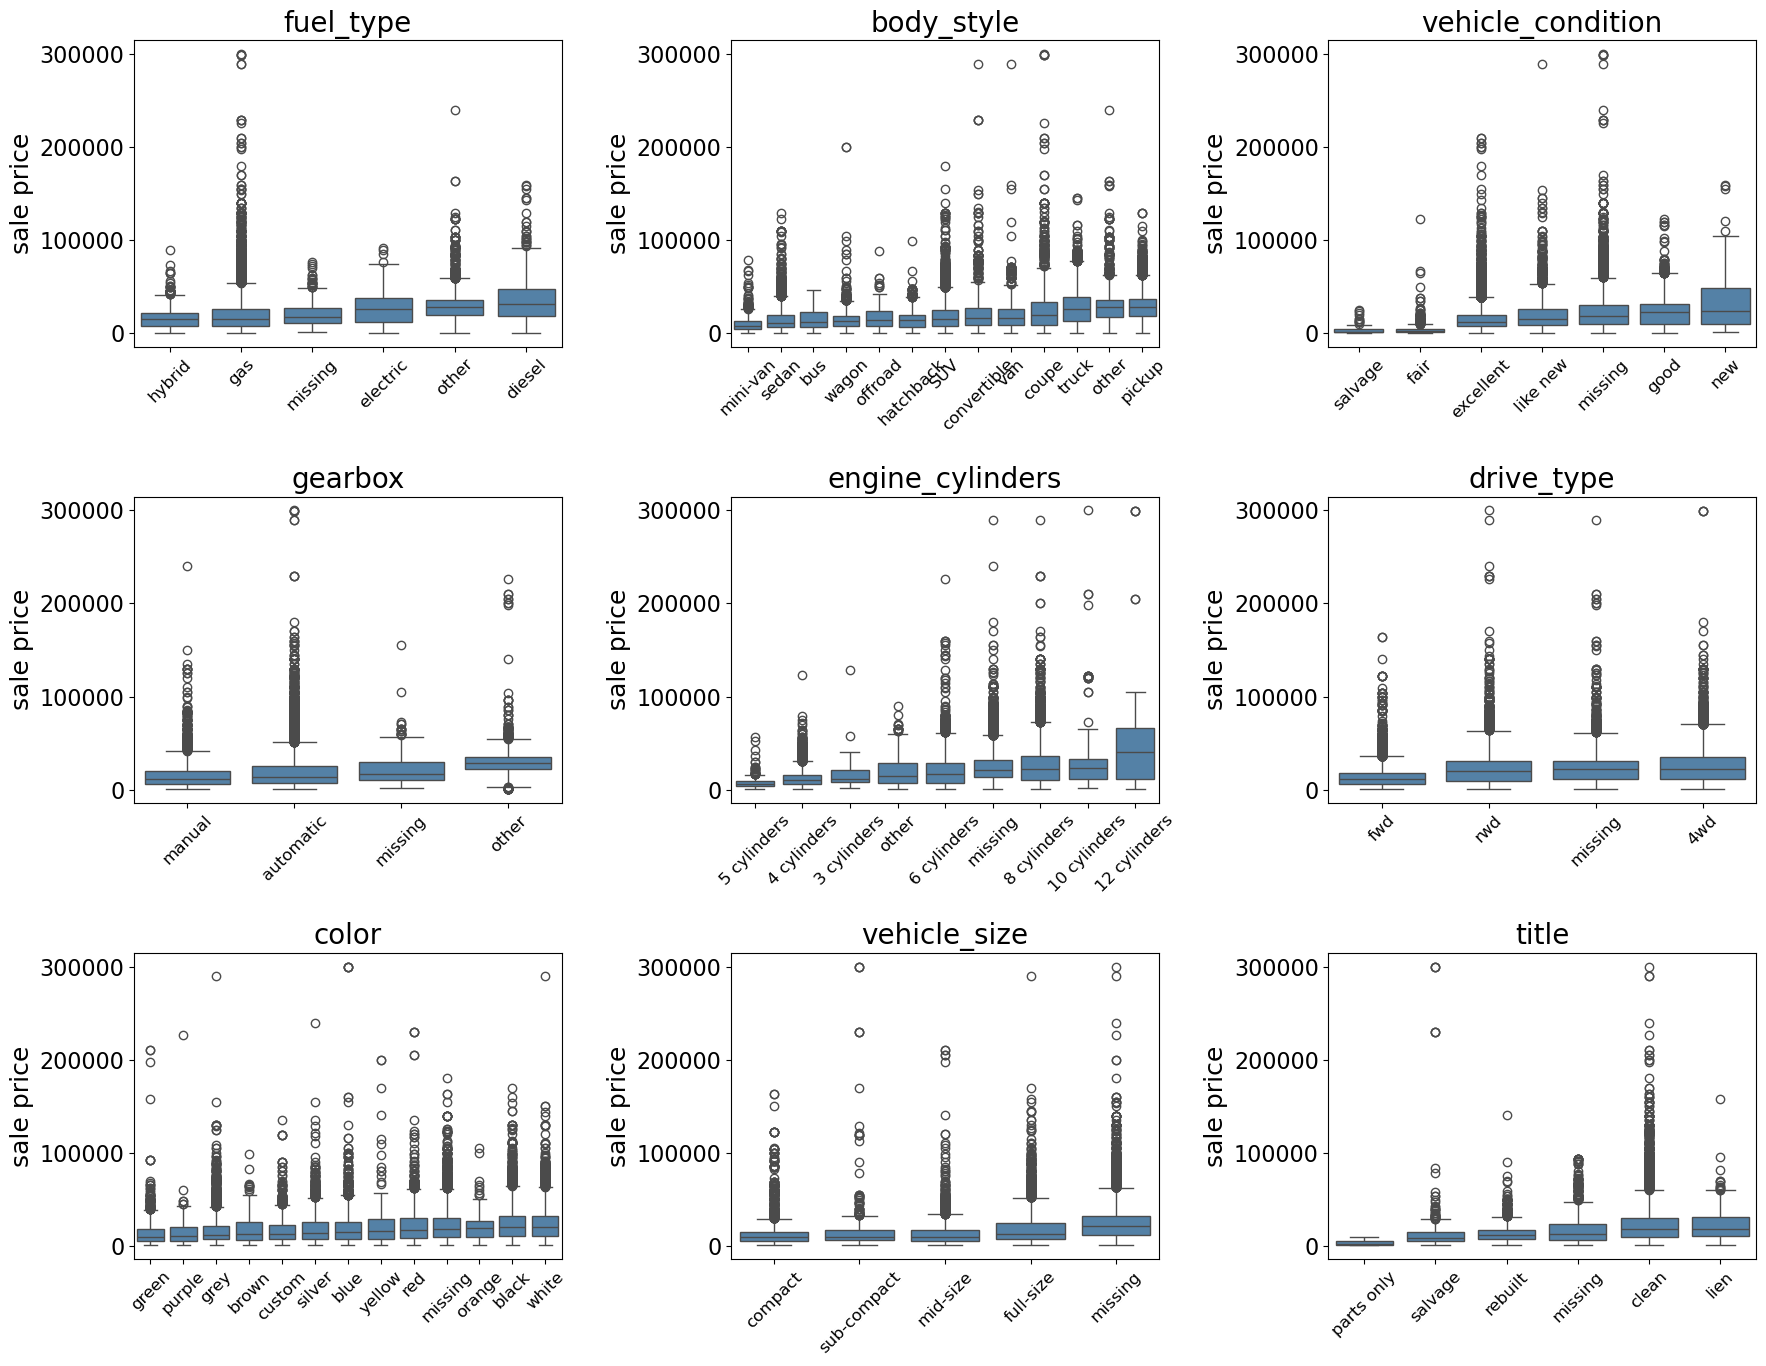

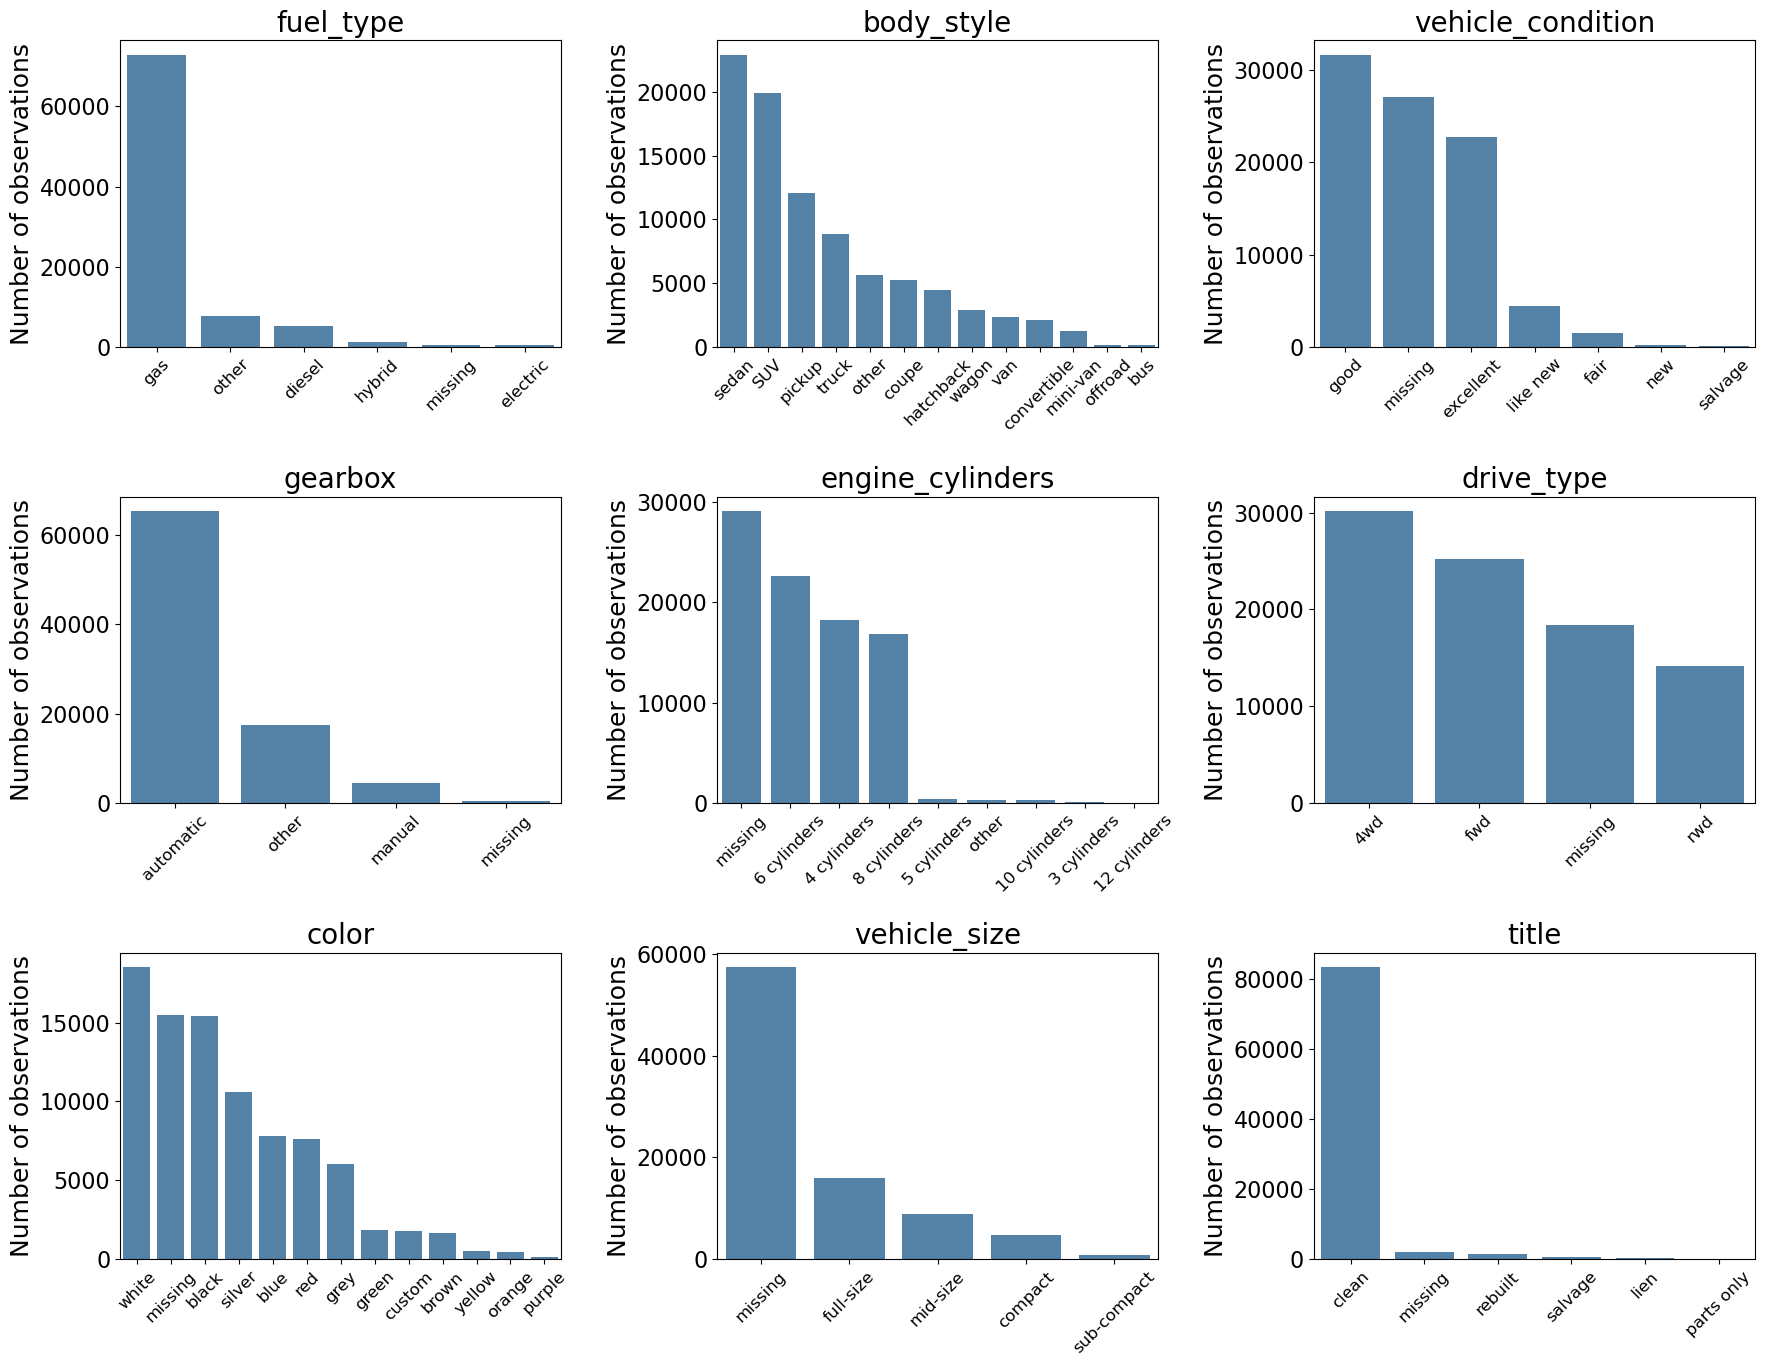

In [ ]:

# Before cleaning visualization! 

rows = []
for col in classes_df.columns:
    counts = df[col].value_counts()          
    n_missing = df[col].isnull().sum()
    top_count = counts.iloc[0]
    rows.append({
        "feature": col,
        "n_unique": df[col].nunique(),
        "most_frequent": counts.index[0],
        "count": top_count,
        "percent": round(top_count / len(df) * 100, 2),
        "n_missing": n_missing,
        "percent_missing": round(n_missing / len(df) * 100, 2),
    })

cat_summary = pd.DataFrame(rows).sort_values("percent", ascending=False)
print(cat_summary.to_string(index=False))
print("Double rows for catagorical values: \n", classes_df.duplicated().sum())

# Boxplot for less than 10 unique values with sales price as target value
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, col in zip(axes.ravel(), classes_df_20.columns):
    plot_df = classes_df_20[[col]].copy()               # double brackets: keeps a DataFrame
    plot_df[col] = classes_df_20[col].fillna("missing")   # NaN as its own box
    plot_df["price"] = df["sale_price"]

    # sort boxes by median price
    order = plot_df.groupby(col)["price"].median().sort_values().index

    sns.boxplot(data=plot_df, x=col, y="price", order=order,
                ax=ax, showfliers=True, color="steelblue")
    ax.set_title(col)
    ax.set_ylabel("sale price")
    #ax.set_yscale("log")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45, labelsize=12)

plt.tight_layout()
plt.savefig("Figures/DataVisualization/boxplots_before.png", dpi=250, bbox_inches="tight")
plt.show()

# Boxplot for less than 10 unique values with sales price as target value
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, col in zip(axes.ravel(), classes_df_20.columns):
    plot_df = classes_df_20[[col]].copy()
    plot_df[col] = plot_df[col].fillna("missing")
    # Sort categories by frequency
    order = plot_df[col].value_counts().index
    sns.countplot(data=plot_df, x=col, order=order, ax=ax, color="steelblue")

    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Number of observations")
    ax.tick_params(axis="x", rotation=45, labelsize=12)

plt.tight_layout()
plt.savefig("Figures/DataVisualization/histograms_categorical_before.png", dpi=250, bbox_inches="tight")
plt.show()



In [ ]:
# --- MISSING VALUES NUMERICAL ---
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
n_before = len(df[num_cols])


0        6 cylinders
1        8 cylinders
2        8 cylinders
3        6 cylinders
4        4 cylinders
            ...     
97326    6 cylinders
97327            NaN
97328    6 cylinders
97329    4 cylinders
97330    8 cylinders
Name: engine_cylinders, Length: 86402, dtype: str


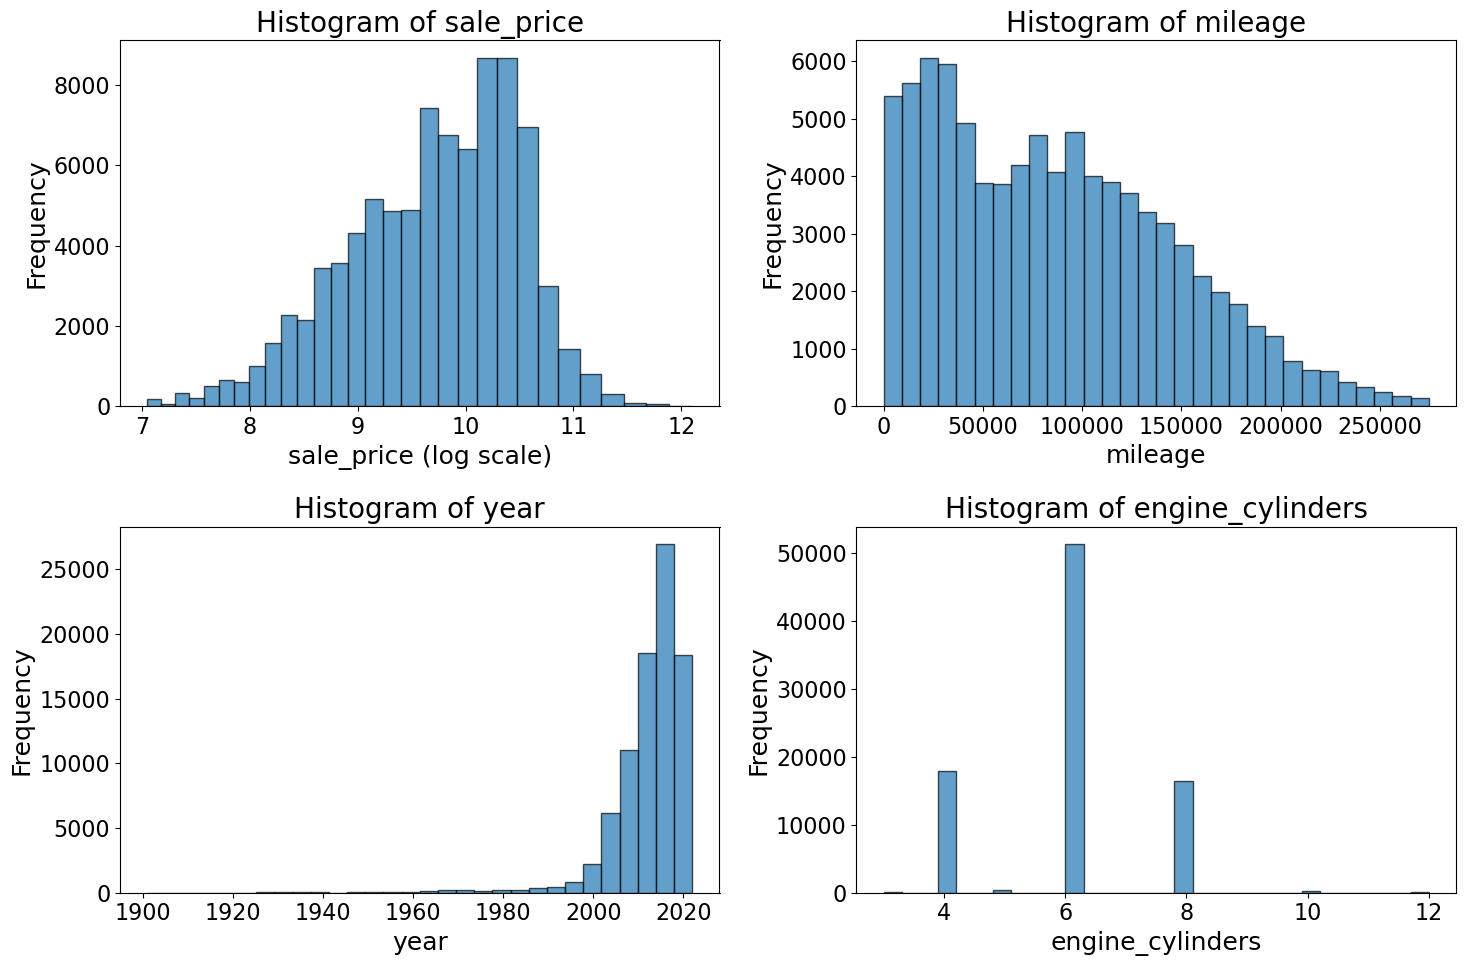

Amount of outliers removed: 
 1429


In [ ]:
import math

# -- NUMERICAL DATA PROCESSING --
# outlier detection z-score
df['sale_price'] = np.log1p(df['sale_price'])
z_score_sale_price = (df['sale_price'] - df['sale_price'].mean()) / df['sale_price'].std()
z_score_mileage = (df['mileage'] - df['mileage'].mean()) / df['mileage'].std()
df = df[(np.abs(z_score_sale_price) <= 3) & (np.abs(z_score_mileage) <= 3)].copy()  # Filter out extreme values based on z-score

# number of engine cylinders processing
print(df["engine_cylinders"])
# Converting a catagroical column to a numerical column due to intrinstic order
df["engine_cylinders"] = df["engine_cylinders"].str.extract(r"(\d+)", expand=False).astype(float)
df["engine_cylinders_status"] = np.where(df["engine_cylinders"].isna(), "Unknown", "Known")
df["engine_cylinders"] = df["engine_cylinders"].fillna(df["engine_cylinders"].median())

# Histograms of the numerical values after cleaning with z-score
numeric_df_after = df.select_dtypes(include=['float64', 'int64'])
n_after = len(numeric_df_after)
n = len(numeric_df_after.columns)
ncols = 2
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 5 * nrows))
axes = np.atleast_1d(axes).flatten()      # must come BEFORE the loop

for i, column in enumerate(numeric_df_after.columns):
    ax = axes[i]
    data = numeric_df_after[column].dropna()

    if column == 'sale_price':
        data = data[data > 0]                       # log scale can't show 0
        bins = np.logspace(np.log10(data.min()), np.log10(data.max()), 31)
        ax.hist(data, bins=bins, edgecolor='black', alpha=0.7)
        #ax.set_xscale('log')
        ax.set_xlabel(f"{column} (log scale)")
    else:
        ax.hist(data, bins=30, edgecolor='black', alpha=0.7)
        ax.set_xlabel(column)

    ax.set_title(f"Histogram of {column}")
    ax.set_ylabel("Frequency")

# hide unused cells
for j in range(n, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig("Figures/DataVisualization/histograms_numerical_after.png", dpi=250, bbox_inches="tight")
plt.show()

print("Amount of outliers removed: \n", n_before - n_after)

In [89]:
df.shape

(86402, 17)

                feature  n_unique most_frequent  count  percent  n_missing  percent_missing
                  title         6         clean  82070    94.99          0              0.0
              fuel_type         6           gas  71780    83.08          0              0.0
                gearbox         4     automatic  64107    74.20          0              0.0
engine_cylinders_status         2         Known  57286    66.30          0              0.0
           vehicle_size         5       missing  56649    65.56          0              0.0
      vehicle_condition         7          good  31324    36.25          0              0.0
             drive_type         4           4wd  29534    34.18          0              0.0
             body_style        13         sedan  22562    26.11          0              0.0
                  color        13         white  18236    21.11          0              0.0
                  brand        42          ford  13510    15.64          0      

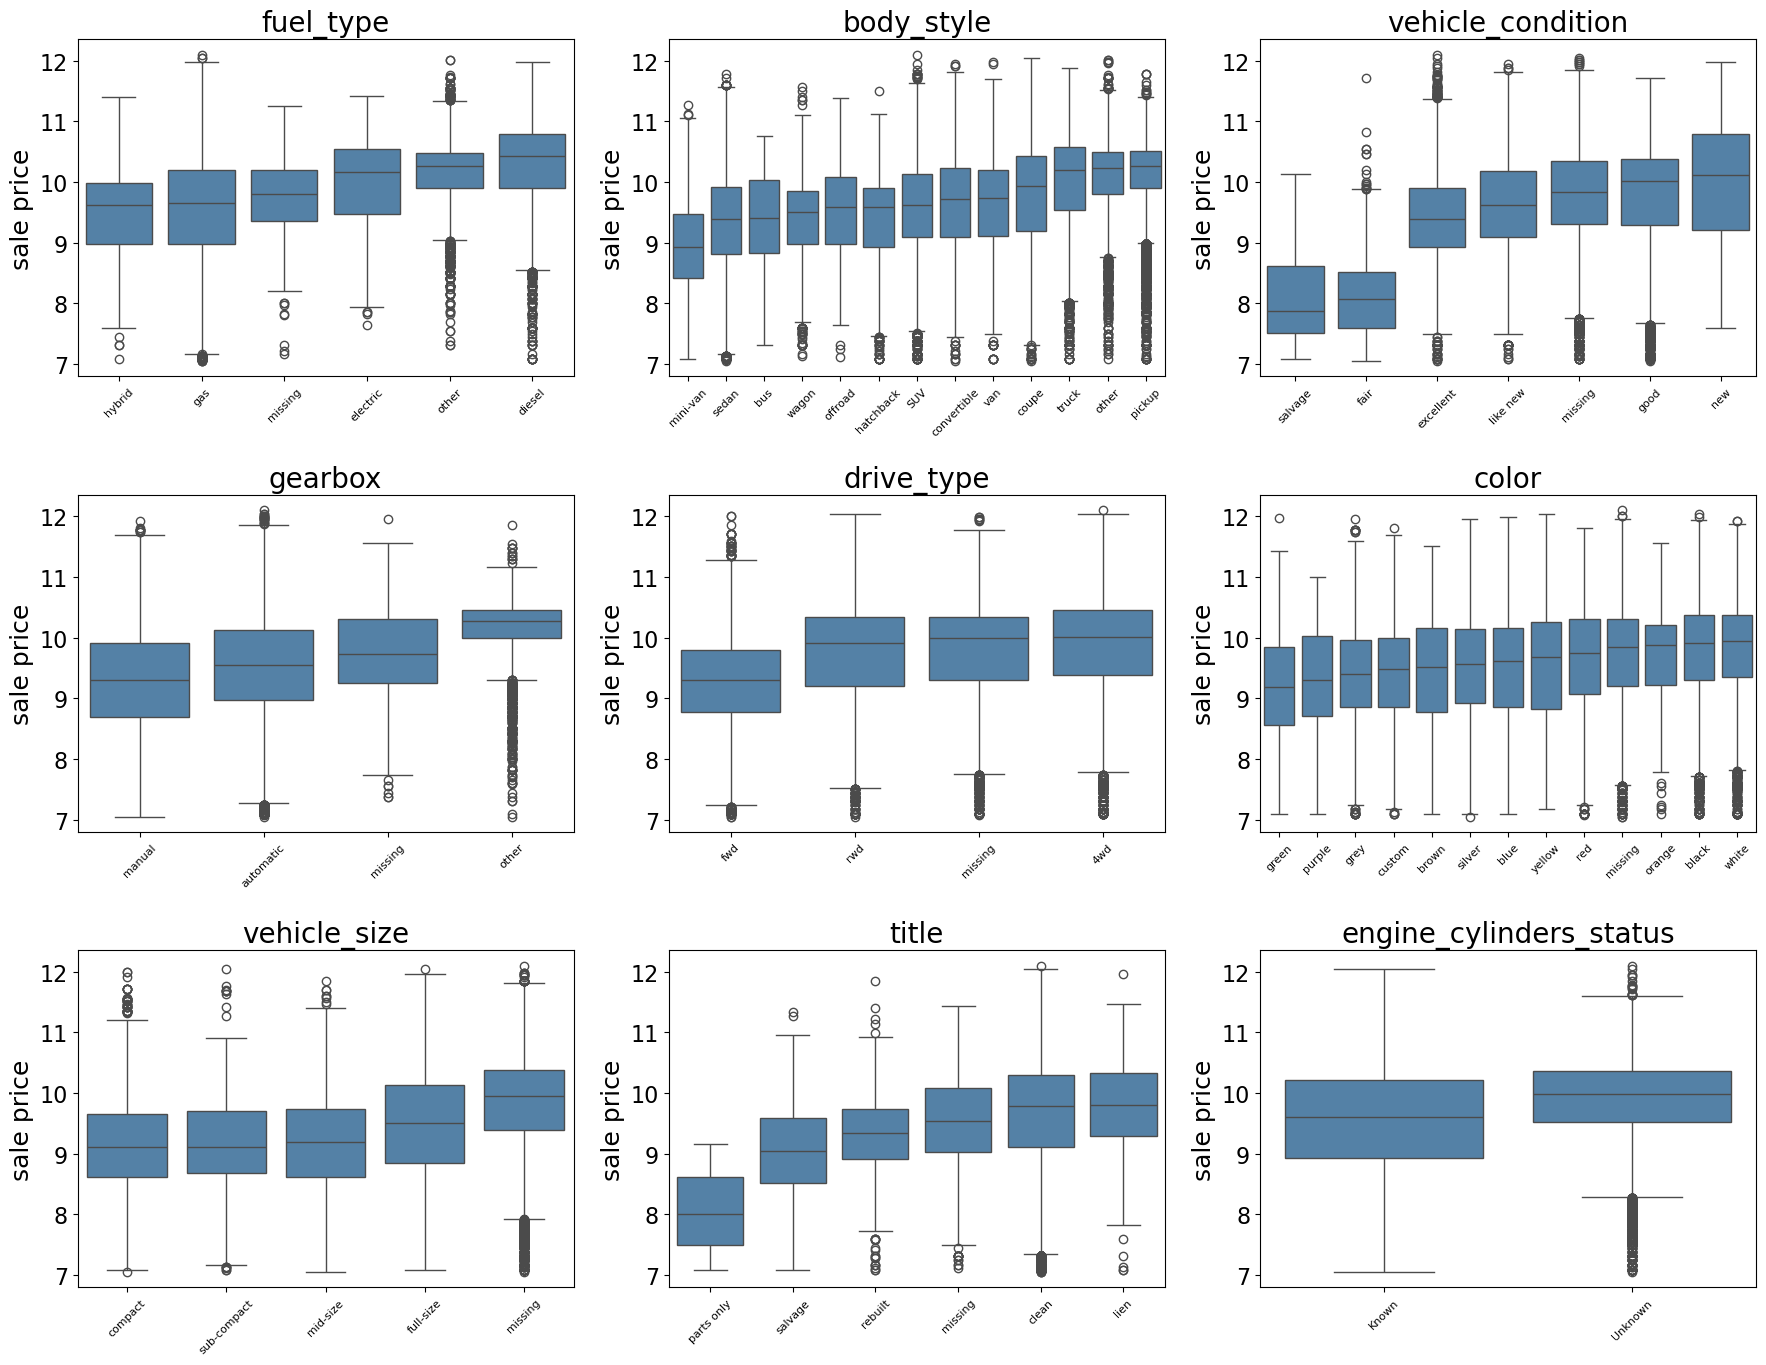

In [ ]:
# -- CATIGORICAL COLUMNS --
df[cat_cols] = df[cat_cols].fillna("missing")

# Looking at the unique values in the categorical columns
classes_df = df.select_dtypes(include=['object'])
cat_cols = classes_df.columns
classes_df_20 = classes_df.loc[:, classes_df.nunique() <= 20] # Selecting all rows and only the columns with < 20 unique values 

# looking at the information of the catagorical columns
rows = []
for col in classes_df.columns:
    counts = df[col].value_counts()          
    n_missing = df[col].isnull().sum()
    top_count = counts.iloc[0]
    rows.append({
        "feature": col,
        "n_unique": df[col].nunique(),
        "most_frequent": counts.index[0],
        "count": top_count,
        "percent": round(top_count / len(df) * 100, 2),
        "n_missing": n_missing,
        "percent_missing": round(n_missing / len(df) * 100, 2),
    })

cat_summary = pd.DataFrame(rows).sort_values("percent", ascending=False)
print(cat_summary.to_string(index=False))
print("Double rows for catagorical values: \n", classes_df.duplicated().sum())

# Boxplot for less than 10 unique values with sales price as target value
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, col in zip(axes.ravel(), classes_df_20.columns):
    plot_df = classes_df_20[[col]].copy()              
    plot_df[col] = classes_df_20[col].fillna("missing")   # filling missing values with missing label
    plot_df["price"] = df["sale_price"]

    # sorting the boxes by their median
    order = plot_df.groupby(col)["price"].median().sort_values().index

    sns.boxplot(data=plot_df, x=col, y="price", order=order,
                ax=ax, showfliers=True, color="steelblue")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("sale price")
    ax.tick_params(axis="x", rotation=45, labelsize=8)

plt.tight_layout()
plt.savefig("Figures/DataVisualization/boxplots_after.png", dpi=250, bbox_inches="tight")
plt.show()


In [ ]:
from sklearn.preprocessing import TargetEncoder
# Trying one hot encoder and target encoder on the catagorical data
num_cols = ["mileage", "year", "engine_cylinders"]
cat_cols_20 = list(classes_df_20.columns)    
catagorical_columns_other = ["brand", "location", "vehicle_model", "region"]

pre = ColumnTransformer(
    [
        ("num", StandardScaler(), num_cols),
        ("cat_ohe", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat_cols_20),
        ("cat_te", TargetEncoder(), catagorical_columns_other )
        
    ],
    remainder="drop",   
)

vehicle_model           0.714824
mileage                -0.623490
year                    0.466817
gearbox_other           0.345172
brand                   0.335989
drive_type_fwd         -0.313391
vehicle_size_missing    0.309462
fuel_type_gas          -0.273934
engine_cylinders        0.271513
gearbox_automatic      -0.266849
dtype: float64


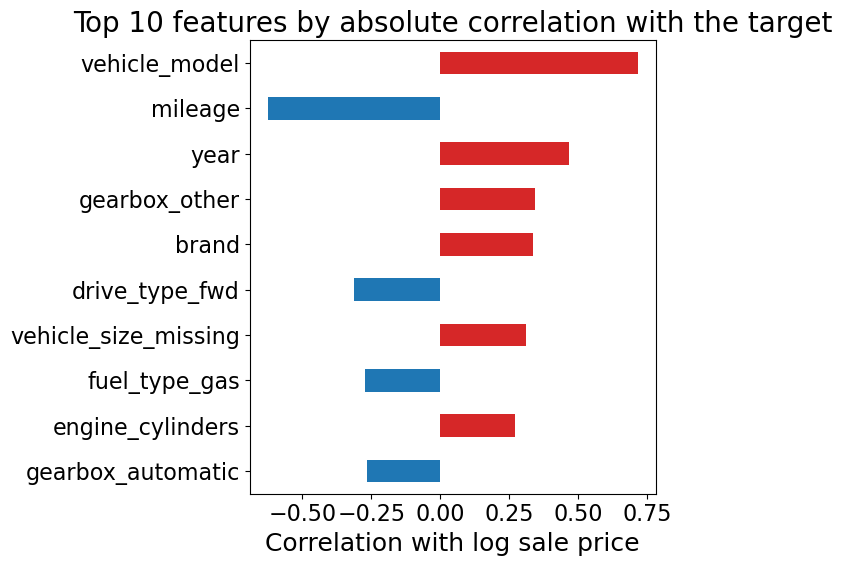

In [92]:
import pandas as pd
import matplotlib.pyplot as plt


X = df.drop(columns=["sale_price"])
y = df["sale_price"]

# encode the whole dataset with the same ColumnTransformer
X_enc = pre.fit_transform(X, y)
if hasattr(X_enc, "toarray"):          # sparse -> dense
    X_enc = X_enc.toarray()

feature_names = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]
enc_df = pd.DataFrame(X_enc, columns=feature_names, index=X.index)

# correlation of every feature with the (log) target, ranked by absolute value
target_corr = enc_df.corrwith(y).sort_values(key=abs, ascending=False)
print(target_corr.head(10))

top = target_corr.head(10)[::-1]
plt.figure(figsize=(7, 6))
top.plot.barh(color=["tab:blue" if v < 0 else "tab:red" for v in top])
plt.xlabel("Correlation with log sale price")
plt.title("Top 10 features by absolute correlation with the target")
plt.tight_layout()
plt.savefig("Figures/DataVisualization/target_correlation.png", dpi=250, bbox_inches="tight")
plt.show()